# Bayesian Classifiers & Generative Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/konstantin-schekotihin/dl_course/blob/master/AI-ML/aux1_BN.ipynb)


In [1]:
# Setup & configuration (skip in presentation slides)
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn.model_selection as sel
import sklearn.metrics as mt
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
import imblearn.over_sampling as ovs

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import aiml as hp
hp.setup_theme()

## 1. Probabilistic Foundations & Bayes' Theorem

### Two Roles for Bayesian Methods in Machine Learning

- Provides practical learning algorithms:
    + Naive Bayes
    + Bayesian belief networks
    + Linear Discriminant Analysis
- Combine prior knowledge (prior probabilities) with observed data
    + Requires prior probabilities
- Provides useful conceptual framework
    + Provides "gold standard" for evaluating other learning algorithms

### Bayes' Theorem in Generative Learning

- Given observed dataset $\mathcal{D}$ and candidate hypotheses $\mathcal{H} = \{h_1, \dots, h_M\}$:
- The **posterior probability** of hypothesis $h$ given data $\mathcal{D}$ is:

$$
p(h \mid \mathcal{D}) = \frac{p(\mathcal{D} \mid h) p(h)}{p(\mathcal{D})}
$$

- **Components of Bayesian Inference**:
  - **Prior $p(h)$**: Initial belief in hypothesis $h$ before observing data.
  - **Likelihood $p(\mathcal{D} \mid h)$**: Probability of observing data $\mathcal{D}$ under hypothesis $h$.
  - **Marginal Evidence $p(\mathcal{D})$**: Normalization factor $p(\mathcal{D}) = \sum_{h' \in \mathcal{H}} p(\mathcal{D} \mid h') p(h')$.
  - **Posterior $p(h \mid \mathcal{D})$**: Updated belief in hypothesis $h$ after observing $\mathcal{D}$.


### Diagnostic Dilemma: Medical Screening Benchmark

> 📘 **Case Study: Diagnostic Testing**
>
> A patient tests positive ($+$) on a diagnostic screening test. The test has:
> - **Sensitivity** (True Positive Rate): $98\%$
> - **False Positive Rate**: $3\%$
> - **Disease Prevalence** in population: $0.8\%$
>
> **Question:** What is the posterior probability that the patient actually has the disease?


### Resolving the Screening Dilemma via Posterior Probabilities

- Prior probabilities and test characteristics:

$$
\begin{aligned}
p(\text{disease}) &= 0.008, & p(\neg \text{disease}) &= 0.992 \\
p(+ \mid \text{disease}) &= 0.98, & p(- \mid \text{disease}) &= 0.02 \\
p(+ \mid \neg \text{disease}) &= 0.03, & p(- \mid \neg \text{disease}) &= 0.97
\end{aligned}
$$

- Evaluating unnormalized posterior likelihoods:

$$
\begin{aligned}
p(\text{disease} \mid +) &\propto p(+ \mid \text{disease}) p(\text{disease}) = 0.98 \times 0.008 = 0.00784 \\
p(\neg \text{disease} \mid +) &\propto p(+ \mid \neg \text{disease}) p(\neg \text{disease}) = 0.03 \times 0.992 = 0.02976
\end{aligned}
$$

- Normalizing: $p(\text{disease} \mid +) = \frac{0.00784}{0.00784 + 0.02976} \approx 20.85\%$.

> 💡 **Key Takeaway:** Even with $98\%$ test sensitivity, when the prior prevalence is low ($0.8\%$), a positive test result only yields a $\approx 21\%$ probability of actual disease.


## 2. Statistical Parameter Estimation: MAP & ML

### Maximum A Posteriori (MAP) Estimation

- The **Maximum A Posteriori (MAP)** hypothesis selects the hypothesis maximizing posterior probability given data $\mathcal{D}$:

$$
\begin{aligned}
h_\mathrm{MAP} &= \arg\max_{h \in \mathcal{H}} p(h \mid \mathcal{D}) \\
&= \arg\max_{h \in \mathcal{H}} \frac{p(\mathcal{D} \mid h) p(h)}{p(\mathcal{D})} \\
&= \arg\max_{h \in \mathcal{H}} p(\mathcal{D} \mid h) p(h)
\end{aligned}
$$

- In our medical screening example: $p(\neg \text{disease} \mid +) > p(\text{disease} \mid +)$, so $h_\mathrm{MAP} = \neg \text{disease}$.


### Maximum Likelihood (ML) Estimation

- Recall **Maximum Likelihood Estimation (MLE)** from fitting logistic regression models *(from Lecture 03)*.
- In Bayesian estimation, when prior probabilities are assumed uniform ($p(h_i) = p(h_j)$ for all hypotheses), the prior term is constant.
- The objective simplifies to the **Maximum Likelihood (ML)** hypothesis:

$$
h_\mathrm{ML} = \arg\max_{h \in \mathcal{H}} p(\mathcal{D} \mid h)
$$

- For medical screening: $p(+ \mid \text{disease}) = 0.98 > p(+ \mid \neg \text{disease}) = 0.03$, yielding $h_\mathrm{ML} = \text{disease}$.

> ⚠️ **Important:** When priors are strongly skewed (e.g. rare diseases, fraudulent transactions), ML estimates can be misleading because they ignore crucial base rates.


## 3. The Bayes Optimal Classifier

- Rather than committing to a single hypothesis $h_\mathrm{MAP}$, what is the most probable class $\mathcal{C}_k$ for query $\mathbf{x}$ taking **all** hypotheses into account?

$$
\mathcal{C}_\mathrm{optimal} = \arg\max_{\mathcal{C}_k \in \mathcal{C}} \sum_{h_i \in \mathcal{H}} p(\mathcal{C}_k \mid h_i) p(h_i \mid \mathcal{D})
$$

- **Optimality Guarantee**: No other classification algorithm trained on the same data with the same prior knowledge can achieve a lower expected error rate.


### Bayes Optimal Classifier: Concrete Example

- Suppose hypotheses $\mathcal{H} = \{h_1, h_2, h_3\}$ have posteriors: $p(h_1 \mid \mathcal{D}) = 0.4$, $p(h_2 \mid \mathcal{D}) = 0.3$, $p(h_3 \mid \mathcal{D}) = 0.3$.
- For a query $\mathbf{x}$, individual predictions are: $h_1(\mathbf{x}) = +$, $h_2(\mathbf{x}) = -$, $h_3(\mathbf{x}) = -$.
- Individual class probabilities:

$$
\begin{aligned}
p(+ \mid \mathcal{D}) &= \sum_{i=1}^{3} p(+ \mid h_i) p(h_i \mid \mathcal{D}) = 1.0 \times 0.4 + 0 + 0 = 0.4 \\
p(- \mid \mathcal{D}) &= \sum_{i=1}^{3} p(- \mid h_i) p(h_i \mid \mathcal{D}) = 0 + 1.0 \times 0.3 + 1.0 \times 0.3 = 0.6
\end{aligned}
$$

- **Decision**: $h_\mathrm{MAP}$ predicts $+$, but the Bayes Optimal Classifier correctly predicts $-$.


### The Gibbs Classifier

- Evaluating all hypotheses in $\mathcal{H}$ for Bayes optimal classification can be computationally prohibitive when $|\mathcal{H}|$ is large.
- **Gibbs Algorithm**:
  1. Sample a single hypothesis $h$ at random according to the posterior distribution $p(h \mid \mathcal{D})$.
  2. Use $h$ to classify the query instance $\mathbf{x}$.

- **Theoretical Bound**: Under uniform concept priors, the expected error of the Gibbs algorithm is bounded by at most twice the expected error of the Bayes Optimal Classifier:

$$
\mathbb{E}[\mathrm{error}_\mathrm{Gibbs}] \le 2 \, \mathbb{E}[\mathrm{error}_\mathrm{Bayes}]
$$


## 4. The Naive Bayes Classifier

- One of the most practical, robust learning algorithms in applied machine learning.
- **Core Idea**: For feature vector $\mathbf{x} = (x_1, \dots, x_D)^\mathrm{T}$ and candidate class $\mathcal{C}_k \in \mathcal{C} = \{\mathcal{C}_1, \dots, \mathcal{C}_K\}$, express joint posterior probability using Bayes' rule:

$$
p(\mathcal{C}_k \mid \mathbf{x}) = \frac{p(\mathcal{C}_k) p(\mathbf{x} \mid \mathcal{C}_k)}{p(\mathbf{x})}
$$

- **The Conditional Independence Assumption**: Assumes all $D$ features are conditionally independent given class label $\mathcal{C}_k$:

$$
p(\mathbf{x} \mid \mathcal{C}_k) = p(x_1, \dots, x_D \mid \mathcal{C}_k) = \prod_{i=1}^{D} p(x_i \mid \mathcal{C}_k)
$$


### The Naive Bayes Decision Rule & Conditional Independence

- Substituting conditional independence into MAP classification:

$$
\begin{aligned}
y(\mathbf{x}) &= \arg\max_{\mathcal{C}_k} p(\mathcal{C}_k \mid x_1, \dots, x_D) \\
&= \arg\max_{\mathcal{C}_k} \frac{p(\mathcal{C}_k) \prod_{i=1}^{D} p(x_i \mid \mathcal{C}_k)}{p(\mathbf{x})} \\
&= \arg\max_{\mathcal{C}_k} p(\mathcal{C}_k) \prod_{i=1}^{D} p(x_i \mid \mathcal{C}_k)
\end{aligned}
$$

- In log-space for numerical stability:

$$
y(\mathbf{x}) = \arg\max_{\mathcal{C}_k} \left[ \ln p(\mathcal{C}_k) + \sum_{i=1}^{D} \ln p(x_i \mid \mathcal{C}_k) \right]
$$


### Training the Naive Bayes Classifier

- For training dataset $\mathcal{D} = \{(\mathbf{x}_n, t_n)\}_{n=1}^N$:
  1. **Estimate Class Priors**:

$$
\hat{p}(\mathcal{C}_k) = \frac{N_k}{N}
$$

  2. **Estimate Feature Conditionals** $\hat{p}(x_i \mid \mathcal{C}_k)$:
     - **Discrete Features**: empirical frequencies in class $\mathcal{C}_k$.
     - **Continuous Features**: Gaussian distribution $\mathcal{N}(\mu_{ki}, \sigma_{ki}^2)$ evaluated via sample mean and variance.


### Why Does Naive Bayes Work So Well in Practice?

- **Violation of Independence**: In practice, feature independence is rarely strictly true.
  - For instance, in weather prediction, *temperature* and *humidity* are correlated.
- **Classification vs. Probability Estimation**:
  - Accurate classification only requires that the **rank order** of class probabilities is correct:

$$
\arg\max_{\mathcal{C}_k} \hat{p}(\mathcal{C}_k \mid \mathbf{x}) = \arg\max_{\mathcal{C}_k} p(\mathcal{C}_k \mid \mathbf{x})
$$

  - Even when posterior probabilities $\hat{p}(\mathcal{C}_k \mid \mathbf{x})$ are pushed unrealistically close to 0 or 1, the winning class prediction remains highly accurate!


### Handling Unseen Features: Laplace Smoothing

- If an attribute value $x_i$ never appears with class $\mathcal{C}_k$ in the training set:
  - The empirical frequency collapses to $\hat{p}(x_i \mid \mathcal{C}_k) = 0$.
  - The product term $\prod_{i=1}^{D} p(x_i \mid \mathcal{C}_k)$ becomes zero, eliminating all other feature evidence!
- **Laplace Smoothing (Pseudocounts)**: Adds pseudo-frequency $\alpha > 0$ (typically $\alpha = 1$):

$$
\hat{p}(x_i \mid \mathcal{C}_k) = \frac{\mathrm{count}(x_i, \mathcal{C}_k) + \alpha}{\sum_{v} \mathrm{count}(v, \mathcal{C}_k) + \alpha V}
$$

  where $V$ is the number of distinct values attribute $x_i$ can assume.


### Applied Benchmark: Iris Dataset

- Classify iris flowers by their species - setosa, versicolor, or virginica - given length and width measurements of their petal and sepal leaves. 

In [2]:
iris = sns.load_dataset("iris")
X = iris.drop(columns="species").to_numpy()
y = iris["species"].to_numpy()

X_train, X_test, y_train, y_test = sel.train_test_split(X, y, test_size=0.25, random_state=42,
                                                        stratify=y)
mn = GaussianNB()
mn.fit(X_train, y_train)
y_pred = mn.predict(X_test)
print(mt.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



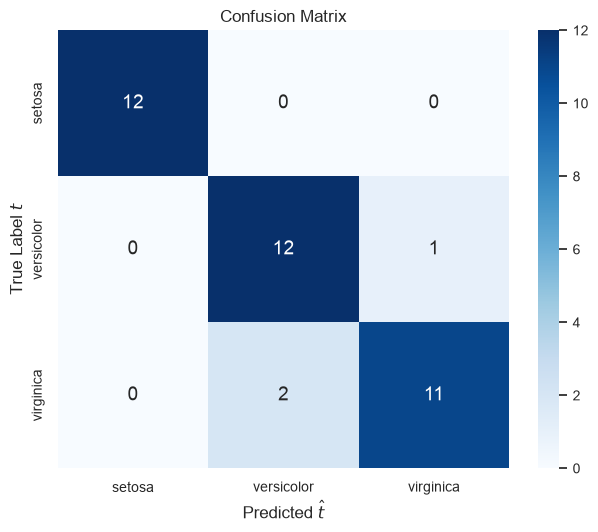

In [3]:
hp.plot_confusion_matrix(y_test, y_pred)

### Applied Benchmark: Breast Cancer Recurrence

- Consider the breast cancer data set that comes with Orange
- the goal is to predict if a tumor might reappear (recurrence-events) or not (no-recurrence-events)

In [4]:
# Load breast cancer dataset
bc = pd.read_csv(hp.get_data_path("breast-cancer.csv"))
bc.head()


,recurrence,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [5]:
bc.describe(include='all')      

,recurrence,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
count,286,286,286,286,286,286,286.000000,286,286,286
unique,2,6,3,11,7,3,NaN,2,6,2
top,no-recurrence-events,50-59,premeno,30-34,0-2,no,NaN,left,left_low,no
freq,201,96,150,60,213,222,NaN,152,110,218
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.048951,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,0.738217,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN


### Categorical Feature Encoding & Oversampling

- Categorical data represented by strings cannot be used in ML directly
- Encode the data into a numerical form

In [6]:

bc = bc.copy()  # Use cached DataFrame

y = bc.pop("recurrence")
X = bc

le = LabelEncoder()
ohe = OneHotEncoder()
le.fit(y)
ohe.fit(X)

X_train, X_test, y_train, y_test = sel.train_test_split(X, y, test_size=0.25, random_state=123)
X_e = ohe.transform(X_train).toarray()
y_e = le.transform(y_train)


# Random oversampling of the minority class (recurrence-events) in the training split; class counts before and after:
print(np.unique(y_e, return_counts=True))
X_e, y_e = ovs.RandomOverSampler(random_state=42).fit_resample(X_e, y_e)
print(np.unique(y_e, return_counts=True))
#mn = MultinomialNB()
mn = GaussianNB()

mn.fit(X_e, y_e)

y_pred = mn.predict(ohe.transform(X_test).toarray())
print(mt.classification_report(le.transform(y_test), y_pred))

(array([0, 1]), array([151,  63]))
(array([0, 1]), array([151, 151]))
              precision    recall  f1-score   support

           0       0.81      0.26      0.39        50
           1       0.34      0.86      0.49        22

    accuracy                           0.44        72
   macro avg       0.58      0.56      0.44        72
weighted avg       0.67      0.44      0.42        72



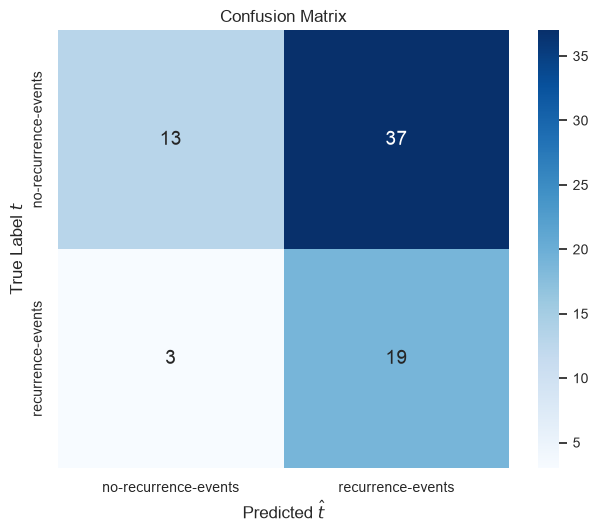

In [7]:
hp.plot_confusion_matrix(le.transform(y_test), y_pred, labels=["no-recurrence-events", "recurrence-events"])


## 5. Algorithm Selection Card: Naive Bayes

| Dimension | Assessment & Practical Guidance |
| :--- | :--- |
| **Best Suited For** | High-dimensional text classification (spam detection, sentiment), categorical tabular data, and lightning-fast baseline models with small-to-moderate training data. |
| **Key Hyperparameters** | • Variant Choice: `GaussianNB` (continuous features), `MultinomialNB` (word counts), `CategoricalNB` (discrete factors).<br>• Smoothing Parameter $\alpha$ (Laplace/Lidstone smoothing) to prevent zero-frequency collapse.<br>• Class Priors (`priors` parameter). |
| **Interpretability vs. Capacity** | **High Interpretability / Low-to-Moderate Capacity**: Transparent probabilistic feature likelihoods; cannot model non-linear feature interactions due to strict independence assumptions. |
| **Critical Pitfalls** | • **Zero Frequency**: Unseen feature-class pairs yield zero probability without Laplace smoothing $\alpha > 0$.<br>• **Correlated Features**: Correlated predictors are counted multiple times, over-confidently skewing posterior probabilities toward 0 or 1. |

> 💡 **Key Takeaway:** Naive Bayes pairs Bayes' theorem with feature conditional independence. It is computationally instantaneous, highly resistant to overfitting on small data, and a vital practical baseline.